In [1]:
# import packages
from scipy.stats import norm
from scipy.stats import chi2
from scipy.special import logit, expit
from statsmodels.api import MNLogit
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families import Poisson
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patsy
import os
from itertools import product
pd.set_option("display.width", 2000)

# import custom functions
from ST5213_helpers import *

In [2]:
tab = pd.read_csv('dataset/contraception.txt', sep=' ')
tab.head()

,Age,None,Sterilization,Other
0,15-19,232,3,61
1,20-24,400,80,137
2,25-29,301,216,131
3,30-34,203,268,76
4,35-39,188,197,50


In [4]:
df = tab.melt(id_vars='Age', var_name='Contraception', value_name='Count')
df['Age'] = pd.Categorical(df['Age'])
df['Contraception'] = pd.Categorical(df['Contraception'])

In [5]:
df_long = df.loc[df.index.repeat(df['Count'])].reset_index(drop=True)
df_long = df_long.drop(columns=['Count'])

In [7]:
df_long['Agen'] = df_long['Age'].str.extract(r'(\d+)\s*-\s*(\d+)').astype(float).mean(axis=1)
df_long['Agec'] = (df_long['Agen'] - 32) / 5

In [10]:
y = df_long['Contraception'].cat.codes
X = patsy.dmatrix(' ', df_long, return_type='dataframe')
fm0 = MNLogit(y, X).fit(disp=False)

In [11]:
X = patsy.dmatrix('Agec', df_long, return_type='dataframe')
fm1 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2)', df_long, return_type='dataframe')
fm2 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3)', df_long, return_type='dataframe')
fm3 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3) + I(Agec**4)', df_long, return_type='dataframe')
fm4 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3) + I(Agec**4) + I(Agec**5)', df_long, return_type='dataframe')
fm5 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3) + I(Agec**4) + I(Agec**5) + I(Agec**6)', df_long, return_type='dataframe')
fm6 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Age', df_long, return_type='dataframe')
fm7 = MNLogit(y, X).fit(disp=False)

In [12]:
print(fm6.llf, fm7.llf)

-2872.8991034461187 -2872.899103446119


In [13]:
print(anova_nested(fm0, fm1, fm2, fm3, fm4, fm5, fm6))

         Resid. Df   Resid. Dev   Df    Deviance      Pr(>Chi)
Model 1     3163.0  6266.900873  NaN         NaN           NaN
Model 2     3161.0  6039.775859  2.0  227.125014  4.791040e-50
Model 3     3159.0  5766.272778  2.0  273.503081  4.069683e-60
Model 4     3157.0  5750.260204  2.0   16.012574  3.333602e-04
Model 5     3155.0  5749.661245  2.0    0.598959  7.412041e-01
Model 6     3153.0  5748.936736  2.0    0.724509  6.961051e-01
Model 7     3151.0  5745.798207  2.0    3.138529  2.081982e-01


In [14]:
print(fm3.params)

                     0         1
Intercept    -0.957883  0.216442
Agec         -0.196922  0.199790
I(Agec ** 2) -0.131708 -0.285527
I(Agec ** 3) -0.007178  0.040532


In [15]:
fm3.deviance = 2*(fm6.llf - fm3.llf)
fm3.df = 2*7 - 2*4
print(chi2.sf(fm3.deviance, fm3.df))

0.6144139310449734


In [18]:
df_long['Agen'].min(), df_long['Agen'].max()

(np.float64(17.0), np.float64(47.0))

In [19]:
Agen_pred = np.array(range(15, 50))
Agec_pred = (Agen_pred - 32) / 5
df_pred = pd.DataFrame({'Agec': Agec_pred, 'Agen': Agen_pred})
Xnew = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3)', df_pred, return_type='dataframe')
fm3_pred = fm3.predict(Xnew)
lo_other = np.log(fm3_pred[1] / fm3_pred[0])
lo_steril = np.log(fm3_pred[2] / fm3_pred[0])

tab['Agen'] = tab['Age'].str.extract(r'(\d+)\s*-\s*(\d+)').astype(float).mean(axis=1)
tab_subset = tab.iloc[:, 1:]
obs_prop = tab_subset.div(tab_subset.sum(axis=1), axis=0)
lo_other_obs = np.log(obs_prop['Other'] / obs_prop['None'])
lo_steril_obs = np.log(obs_prop['Sterilization'] / obs_prop['None'])

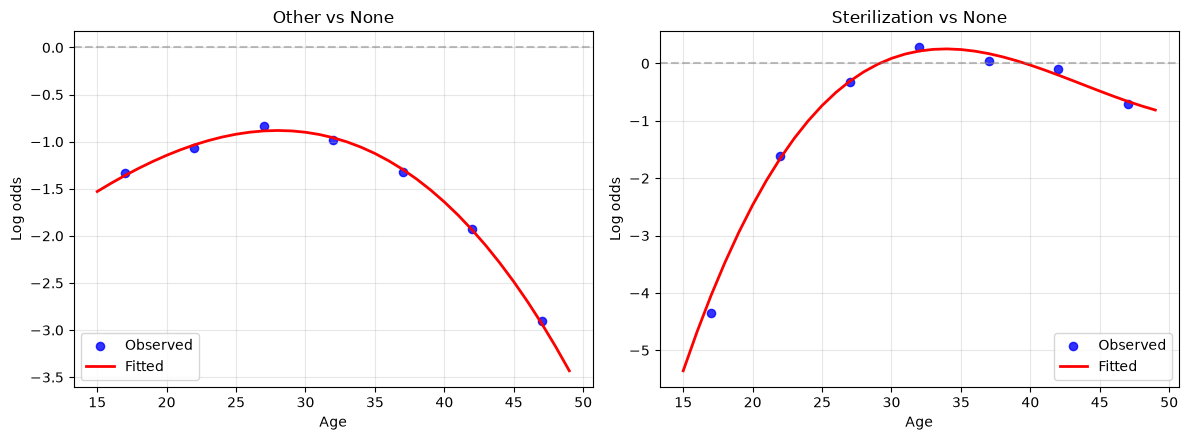

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

categories = [
    ('Other', lo_other_obs, lo_other),
    ('Sterilization', lo_steril_obs, lo_steril)
]

for ax, (category, obs, fitted) in zip(axes, categories):
    # Observed log odds
    ax.scatter(tab['Agen'], obs, color='blue',
               label='Observed', s=35, alpha=0.8)

    # Fitted log odds
    ax.plot(Agen_pred, fitted, color='red',
            label='Fitted', linewidth=2)

    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_xlabel('Age')
    ax.set_ylabel('Log odds')
    ax.set_title(f'{category} vs None')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
Agec40 = (40 - 32) / 5
pred40 = pd.DataFrame({'Agec': [Agec40]})
Xnew_40 = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3)', pred40, return_type='dataframe')
fm3_pred40 = fm3.predict(Xnew_40)
print(fm3_pred40)

          0         1         2
0  0.461753  0.089613  0.448634


In [24]:
print(fm3_pred40[2] / fm3_pred40[1])

0    5.006367
dtype: float64


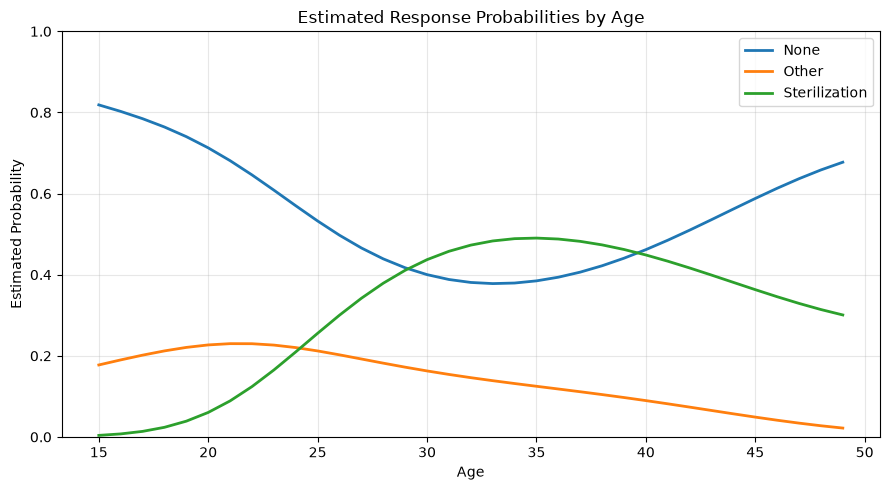

In [25]:
plt.figure(figsize=(9, 5))

categories = ['None', 'Other', 'Sterilization']

for i, category in enumerate(categories):
    plt.plot(Agen_pred, fm3_pred.iloc[:, i],
             linewidth=2, label=category)

plt.xlabel('Age')
plt.ylabel('Estimated Probability')
plt.title('Estimated Response Probabilities by Age')
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
tab['Agec'] = (tab['Agen'] - 32) / 5
tab['None_cnt'] = tab['None']
tab['Any'] = tab['Other'] + tab['Sterilization']

fm0 = glm('Any + None_cnt ~ 1', tab, family=Binomial()).fit()
fm1 = update_glm(fm0, add='Agec')
fm2 = update_glm(fm1, add='I(Agec**2)')
fm3 = update_glm(fm2, add='I(Agec**3)')
fm4 = update_glm(fm3, add='I(Agec**4)')
fm5 = update_glm(fm4, add='I(Agec**5)')
fm6 = update_glm(fm5, add='I(Agec**6)')
print(anova_nested(fm0, fm1, fm2, fm3, fm4, fm5, fm6))

         Resid. Df    Resid. Dev   Df    Deviance      Pr(>Chi)
Model 1        6.0  2.188388e+02  NaN         NaN           NaN
Model 2        5.0  1.808546e+02  1.0   37.984177  7.132069e-10
Model 3        4.0  6.119465e+00  1.0  174.735175  6.839712e-40
Model 4        3.0  6.041849e+00  1.0    0.077617  7.805534e-01
Model 5        2.0  3.150511e+00  1.0    2.891337  8.905699e-02
Model 6        1.0  1.136427e+00  1.0    2.014084  1.558453e-01
Model 7        0.0 -9.614531e-14  1.0    1.136427  2.864086e-01


c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


In [27]:
print(fm2.summary2())

               Results: Generalized linear model
Model:              GLM                 Method:         IRLS   
Model Family:       Binomial            AIC:            57.0704
Link Function:      Logit               BIC:            56.9081
Dependent Variable: ['Any', 'None_cnt'] Log-Likelihood: -25.535
Date:               2026-11-03 10:28    LL-Null:        -131.89
No. Observations:   7                   Deviance:       6.1195 
Df Model:           2                   Pearson chi2:   6.12   
Df Residuals:       4                   Scale:          1.0000 
---------------------------------------------------------------
                Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
---------------------------------------------------------------
Intercept       0.4095   0.0525   7.8042 0.0000  0.3067  0.5124
Agec            0.1367   0.0216   6.3320 0.0000  0.0944  0.1790
I(Agec ** 2)   -0.1586   0.0125 -12.7108 0.0000 -0.1831 -0.1342



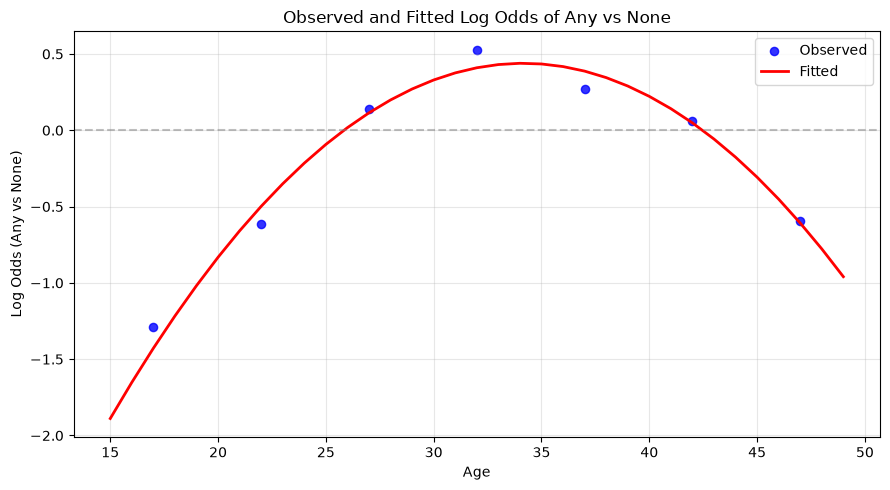

In [29]:
df_pred = pd.DataFrame({'Agec': Agec_pred})
p_pred = fm2.predict(df_pred)
lo_pred = np.log(p_pred / (1 - p_pred))
lo_obs = np.log(tab['Any'] / tab['None_cnt'])

plt.figure(figsize=(9, 5))

plt.scatter(tab['Agen'], lo_obs, color='blue',
            label='Observed', s=35, alpha=0.8)

plt.plot(Agen_pred, lo_pred, color='red',
         label='Fitted', linewidth=2)

plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

plt.xlabel('Age')
plt.ylabel('Log Odds (Any vs None)')
plt.title('Observed and Fitted Log Odds of Any vs None')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
fm0 = glm('Sterilization + Other ~ 1', tab, family=Binomial()).fit()
fm1 = update_glm(fm0, add='Agec')
fm2 = update_glm(fm1, add='I(Agec**2)')
fm3 = update_glm(fm2, add='I(Agec**3)')
fm4 = update_glm(fm3, add='I(Agec**4)')
fm5 = update_glm(fm4, add='I(Agec**5)')
fm6 = update_glm(fm5, add='I(Agec**6)')
print(anova_nested(fm0, fm1, fm2, fm3, fm4, fm5, fm6))

         Resid. Df    Resid. Dev   Df    Deviance      Pr(>Chi)
Model 1        6.0  3.022638e+02  NaN         NaN           NaN
Model 2        5.0  4.161491e+01  1.0  260.648943  1.238976e-58
Model 3        4.0  1.077352e+01  1.0   30.841390  2.800016e-08
Model 4        3.0  2.129860e+00  1.0    8.643656  3.282022e-03
Model 5        2.0  1.935556e+00  1.0    0.194303  6.593591e-01
Model 6        1.0  1.804838e+00  1.0    0.130718  7.176883e-01
Model 7        0.0  4.685141e-14  1.0    1.804838  1.791287e-01


c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


In [31]:
print(fm3.summary2())

                  Results: Generalized linear model
Model:              GLM                        Method:         IRLS   
Model Family:       Binomial                   AIC:            45.4531
Link Function:      Logit                      BIC:            45.2367
Dependent Variable: ['Sterilization', 'Other'] Log-Likelihood: -18.727
Date:               2026-11-03 10:33           LL-Null:        -168.79
No. Observations:   7                          Deviance:       2.1299 
Df Model:           3                          Pearson chi2:   2.10   
Df Residuals:       3                          Scale:          1.0000 
------------------------------------------------------------------------
                Coef.    Std.Err.      z      P>|z|     [0.025    0.975]
------------------------------------------------------------------------
Intercept       1.1738     0.0844   13.9011   0.0000    1.0083    1.3393
Agec            0.3971     0.0894    4.4397   0.0000    0.2218    0.5724
I(Agec ** 2)   

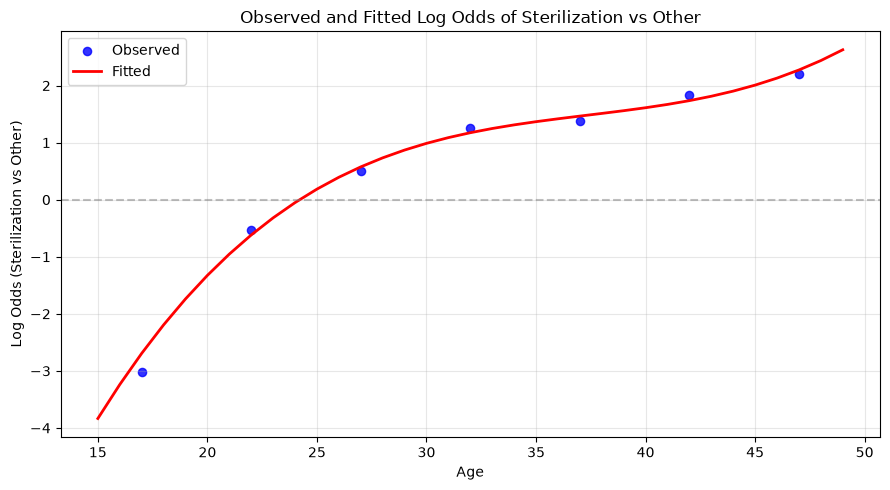

In [32]:
p_pred = fm3.predict(df_pred)
lo_pred = np.log(p_pred / (1 - p_pred))
lo_obs = np.log(tab['Sterilization'] / tab['Other'])

plt.figure(figsize=(9, 5))

plt.scatter(tab['Agen'], lo_obs, color='blue',
            label='Observed', s=35, alpha=0.8)

plt.plot(Agen_pred, lo_pred, color='red',
         label='Fitted', linewidth=2)

plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

plt.xlabel('Age')
plt.ylabel('Log Odds (Sterilization vs Other)')
plt.title('Observed and Fitted Log Odds of Sterilization vs Other')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()